In [9]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [10]:
# import mne

from pathlib import Path

import mne
import matplotlib
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from src.dataset_utils import build_manifest, save_manifest

standardize = lambda x: (x - x.mean()) / x.std()

In [11]:
manifest = pd.read_csv("C:/Users/MDBI/Documents/public-datasets/sleepy-rat/manifest.csv")  


In [12]:
manifest

,cohort,animal_id,edf_path,scoring_path,has_scoring
0,CohortA,A1,C:\Users\MDBI\Documents\public-datasets\sleepy...,C:\Users\MDBI\Documents\public-datasets\sleepy...,True
1,CohortA,A2,C:\Users\MDBI\Documents\public-datasets\sleepy...,C:\Users\MDBI\Documents\public-datasets\sleepy...,True
2,CohortA,A3,C:\Users\MDBI\Documents\public-datasets\sleepy...,C:\Users\MDBI\Documents\public-datasets\sleepy...,True
3,CohortA,A4,C:\Users\MDBI\Documents\public-datasets\sleepy...,C:\Users\MDBI\Documents\public-datasets\sleepy...,True
4,CohortB,B1,C:\Users\MDBI\Documents\public-datasets\sleepy...,C:\Users\MDBI\Documents\public-datasets\sleepy...,True
5,CohortB,B2,C:\Users\MDBI\Documents\public-datasets\sleepy...,C:\Users\MDBI\Documents\public-datasets\sleepy...,True
6,CohortB,B3,C:\Users\MDBI\Documents\public-datasets\sleepy...,C:\Users\MDBI\Documents\public-datasets\sleepy...,True
7,CohortB,B4,C:\Users\MDBI\Documents\public-datasets\sleepy...,C:\Users\MDBI\Documents\public-datasets\sleepy...,True
8,CohortC,C1,C:\Users\MDBI\Documents\public-datasets\sleepy...,C:\Users\MDBI\Documents\public-datasets\sleepy...,True
9,CohortC,C2,C:\Users\MDBI\Documents\public-datasets\sleepy...,C:\Users\MDBI\Documents\public-datasets\sleepy...,True


In [13]:
df_test = manifest.head(2)

In [16]:
from src.eeg_preprocessing import preprocess_eeg
from src.utils import load_edf_signals, ensure_dir, save_feature_matrix_npz

df = df_test

OUTPUT_ROOT = Path("outputs/spectrograms")  # change as you like
df["feature_matrix_path"]   = None   # single .npz containing concatenated features

outer = []
for idx, row in df.iterrows():
    animal_id = row['animal_id']
    print(f'Processing {animal_id} ...')

    ch_names, fs_list, raw_signals = load_edf_signals(row["edf_path"])
    sf = float(fs_list[0])  # assuming all channels share same sf

    # Make a folder per recording
    rec_dir = ensure_dir(OUTPUT_ROOT / animal_id)

    preprocessed_signals = []
    for signal in raw_signals:
        f, t, S = preprocess_eeg(
                                signal,
                                win_sec=1.0,
                                overlap_sec=0.0,
                                multi_taper=True,
                                sampling_freq_hz=fs_list[0],
                                low_cut_hz=0.5,
                                high_cut_hz=60.0,
                                notch_low_cut_hz=45.0,
                                notch_high_cut_hz=55.0,
                                normalize_method='z-score',
                                normalize_p=5.0
                                )
                    
        preprocessed_signals.append(S)

        plot_spectrogram(f, t, S, title=f"{row['animal_id']}", show=True)
    
    preprocessed_signals = np.concatenate([signal.T for signal in preprocessed_signals], axis=1)
    outer.append(preprocessed_signals)

    # Save feature matrix once per recording
    feat_path = rec_dir / f"{animal_id}__features_concat.npz"
    save_feature_matrix_npz(
        feat_path, X,
        meta=dict(animal_id=animal_id, sfreq=sf, n_channels=len(ch_names))
    )


    df.at[idx, "feature_matrix_path"]   = str(feat_path)

TypeError: unsupported operand type(s) for |: 'type' and 'type'

In [ ]:
import json
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

from src.eeg_preprocessing import preprocess_eeg
from src.utils import load_edf_signals, ensure_dir, save_feature_matrix_npz
# assume you already have a plot_spectrogram(f, t, S, ...) util

df = manifest

OUTPUT_ROOT = Path("outputs/spectrograms")
df["feature_matrix_path"] = None

for idx, row in df.iterrows():
    animal_id = str(row["animal_id"])
    print(f"Processing {animal_id} ...")

    labels_df = get_annotations(row["scoring_path"], consensus_rule="priority")

    ch_names, fs_list, raw_signals = load_edf_signals(row["edf_path"])
    sf = float(fs_list[0])

    rec_dir = ensure_dir(OUTPUT_ROOT / animal_id)

    S_list = []
    for ch_name, signal in zip(ch_names, raw_signals):
        f, t, S = preprocess_eeg(
            signal,
            win_sec=1.0, overlap_sec=0.0, multi_taper=True,
            sampling_freq_hz=sf,
            low_cut_hz=0.5, high_cut_hz=60.0,
            notch_low_cut_hz=45.0, notch_high_cut_hz=55.0,
            normalize_method="z-score", normalize_p=5.0
        )
        # Save a PNG (don’t block)
        png_path = rec_dir / f"{animal_id}__{ch_name}__spectrogram.png"
        plot_spectrogram(f, t, S, title=f"{animal_id} — {ch_name}", out_png=png_path, show=False)

        S_list.append(S.astype(np.float32))

    # Concatenate features across channels: stack frequency bins along columns
    # Each S is (F x T). Transpose to (T x F) then concat along feature axis.
    X = np.concatenate([S.T for S in S_list], axis=1).astype(np.float32)  # shape: (T, F_total)

    X_epochs = concat_every_k_rows(X, k=4)      # (T//4, 4*F_total)
    y_epochs = align_labels(labels_df["stage"], n_epochs=len(X_epochs))

    # Save per-recording feature matrix
    feat_path = rec_dir / f"{animal_id}__features_concat.npz"
    save_feature_matrix_npz(
        feat_path, X,
        meta=dict(animal_id=animal_id, sfreq=sf, n_channels=len(ch_names))
    )
    df.at[idx, "feature_matrix_path"] = str(feat_path)


Processing A1 ...
Processing A2 ...


In [21]:
df

,cohort,animal_id,edf_path,scoring_path,has_scoring,feature_matrix_path
0,CohortA,A1,C:\Users\MDBI\Documents\public-datasets\sleepy...,C:\Users\MDBI\Documents\public-datasets\sleepy...,True,outputs\spectrograms\A1\A1__features_concat.npz
1,CohortA,A2,C:\Users\MDBI\Documents\public-datasets\sleepy...,C:\Users\MDBI\Documents\public-datasets\sleepy...,True,outputs\spectrograms\A2\A2__features_concat.npz


In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path

from src.eeg_preprocessing import preprocess_eeg, concat_every_k_rows, align_labels, make_epoch_dataframe, get_annotations
from src.utils import load_edf_signals, ensure_dir, save_feature_matrix_npz, plot_spectrogram


# -------- config --------
SAVE_SPECTROGRAM_PNGS = False  # set True if you want QC images
OUTPUT_ROOT = Path("outputs/spectrograms")
BIG_DATASET_OUT = Path("outputs/all_recordings_epochs.parquet")  # will fall back to pickle if pyarrow missing

# Your input dataframe
df = manifest.copy()

# Optional: keep per-recording NPZ paths (can be useful for debugging)
df["feature_matrix_path"] = None

parts = []  # collect per-recording epoch DataFrames

for idx, row in df.iterrows():
    animal_id = str(row["animal_id"])
    print(f"Processing {animal_id} ...")

    # Load labels (one per 4 s)
    labels_df = get_annotations(row["scoring_path"], consensus_rule="priority")
    y_all = labels_df["stage"].to_numpy()

    # Load signals
    ch_names, fs_list, raw_signals = load_edf_signals(row["edf_path"])
    sf = float(fs_list[0])  # assume same sf for all channels

    # Output dir for this recording
    rec_dir = ensure_dir(OUTPUT_ROOT / animal_id)

    # Build spectrogram features per channel
    S_list = []
    for ch_name, signal in zip(ch_names, raw_signals):
        f, t, S = preprocess_eeg(
            signal,
            win_sec=1.0, overlap_sec=0.0, multi_taper=True,
            sampling_freq_hz=sf,
            low_cut_hz=0.5, high_cut_hz=60.0,  # keep <= 60 so 128 Hz files are compatible
            notch_low_cut_hz=45.0, notch_high_cut_hz=55.0,
            normalize_method="z-score", normalize_p=5.0
        )

        if SAVE_SPECTROGRAM_PNGS:
            png_path = rec_dir / f"{animal_id}__{ch_name}__spectrogram.png"
            plot_spectrogram(f, t, S, title=f"{animal_id} — {ch_name}", out_png=png_path, show=False)

        S_list.append(S.astype(np.float32))

    # Concatenate channels: (F x T) -> (T x F) per channel, then concat along feature axis
    X = np.concatenate([S.T for S in S_list], axis=1).astype(np.float32)  # shape: (T, F_total)

    # # Optional: save per-recording feature matrix for debugging/traceability
    # feat_path = rec_dir / f"{animal_id}__features_concat.npz"
    # save_feature_matrix_npz(
    #     feat_path, X,
    #     meta=dict(animal_id=animal_id, sfreq=sf, n_channels=len(ch_names))
    # )
    # df.at[idx, "feature_matrix_path"] = str(feat_path)

    # Fold 1-s frames -> 4-s concatenated epochs and align labels
    X_epochs = concat_every_k_rows(X, k=4)                  # (E, 4*F_total)
    y_epochs = align_labels(y_all, n_epochs=len(X_epochs))  # (E,)

    # Build per-recording DF and collect
    parts.append(make_epoch_dataframe(animal_id, X_epochs, y_epochs, epoch_len_sec=4))

# Stack everything into one big DataFrame
big_df = pd.concat(parts, ignore_index=True)

# -------- save the big dataset --------
# Try Parquet for efficient storage; fall back to Pickle if pyarrow isn't available.
# BIG_DATASET_OUT.parent.mkdir(parents=True, exist_ok=True)
# try:
#     big_df.to_parquet(BIG_DATASET_OUT, index=False)  # requires pyarrow or fastparquet
#     print(f"Saved dataset to {BIG_DATASET_OUT} (Parquet).")
# except Exception as e:
#     pkl_path = BIG_DATASET_OUT.with_suffix(".pkl")
#     big_df.to_pickle(pkl_path)
#     print(f"Parquet save failed ({e}). Saved Pickle instead: {pkl_path}")

Processing A1 ...
Processing A2 ...
Processing A3 ...
Processing A4 ...
Processing B1 ...
Processing B2 ...
Processing B3 ...
Processing B4 ...
Processing C1 ...
Processing C2 ...
Processing C3 ...
Processing C4 ...
Processing C5 ...
Processing C6 ...
Processing C7 ...
Processing C8 ...
Processing D1 ...
Processing D2 ...
Processing D3 ...
Processing D4 ...
Processing D5 ...
Processing D6 ...


In [39]:
print(big_df.shape)
big_df_no_artifacts = big_df[big_df.label != 'Unknown']

print(big_df_no_artifacts.shape)

(475200, 5)
(445329, 5)


In [44]:
import numpy as np
import pandas as pd
from src.prediction_utils import encode_stages, decode_stages

def df_to_xy(big_df: pd.DataFrame, encode_labels: bool = False):
    # sanity: all feature lengths equal
    lens = big_df["features"].map(lambda a: int(a.size))
    if lens.nunique() != 1:
        raise ValueError(f"Inconsistent feature lengths: {lens.value_counts().to_dict()}")
    D = lens.iloc[0]
    N = len(big_df)

    # stack features into (N, D)
    # NOTE: .values is an object array of 1D arrays → np.stack builds the 2D matrix
    X = np.stack(big_df["features"].values).astype(np.float32, copy=False)

    # labels
    y = big_df["label"].to_numpy()
    y_enc = encode_stages(y)
    # if encode_labels and not np.issubdtype(y.dtype, np.number):
    #     # optional: turn strings into ints
    #     from sklearn.preprocessing import LabelEncoder
    #     le = LabelEncoder()
    #     y = le.fit_transform(y)
    #     # keep the mapping if you want:
    #     label_map = dict(zip(le.classes_, range(len(le.classes_))))
    # else:
    #     label_map = None

    # groups for group-wise splits (avoid leakage across animals)
    groups = big_df["animal_id"].astype(str).to_numpy()

    return X, y_enc, groups, label_map

# Usage
X, y, groups, label_map = df_to_xy(big_df_no_artifacts, encode_labels=True)
print(X.shape, y.shape)

(445329, 588) (445329,)


In [45]:
from src.split_data import make_group_splits

# Load groups (animal IDs) you saved earlier alongside the specs
idx_tr, idx_va, idx_te = make_group_splits(y, groups, n_splits=5, random_state=42)

# Slice the memmaps (this does not load everything into RAM at once)
X_tr, y_tr_enc = X[idx_tr], y[idx_tr]
X_va, y_va_enc = X[idx_va], y[idx_va]
X_te, y_te_enc = X[idx_te], y[idx_te]

print("Train/Val/Test:", X_tr.shape, X_va.shape, X_te.shape)

Train/Val/Test: (270504, 588) (99549, 588) (75276, 588)


In [46]:
import numpy as np

def animals_in_split(groups, idx):
    g = np.asarray(groups)
    u, counts = np.unique(g[idx], return_counts=True)
    return u, counts  # unique animal IDs and their epoch counts

train_animals, train_counts = animals_in_split(groups, idx_tr)
val_animals,   val_counts   = animals_in_split(groups, idx_va)
test_animals,  test_counts  = animals_in_split(groups, idx_te)

print("Train: n_animals =", len(train_animals))
print("Val:   n_animals =", len(val_animals))
print("Test:  n_animals =", len(test_animals))

# (optional) peek the lists
print("Train animals:", train_animals[:10])
print("Val animals:  ", val_animals[:10])
print("Test animals: ", test_animals[:10])

Train: n_animals = 13
Val:   n_animals = 5
Test:  n_animals = 4
Train animals: ['A1' 'A3' 'B4' 'C1' 'C4' 'C6' 'C7' 'D1' 'D2' 'D3']
Val animals:   ['B1' 'B2' 'B3' 'C5' 'C8']
Test animals:  ['A2' 'A4' 'C2' 'C3']


In [47]:
import numpy as np

def label_ratios(y, idx):
    y_idx = np.asarray(y)[idx]
    vals, cnts = np.unique(y_idx, return_counts=True)
    total = int(cnts.sum())
    return {int(v): (c / total if total else 0.0) for v, c in zip(vals, cnts)}

def fmt_ratios(d, decimals=1):
    parts = [f"{k}: {v*100:.{decimals}f}%" for k, v in sorted(d.items())]
    return "{" + ", ".join(parts) + "}"

print("Train labels:", fmt_ratios(label_ratios(y, idx_tr)))
print("Val labels:  ", fmt_ratios(label_ratios(y, idx_va)))
print("Test labels: ", fmt_ratios(label_ratios(y, idx_te)))

Train labels: {0: 45.1%, 1: 47.5%, 2: 7.5%}
Val labels:   {0: 45.4%, 1: 47.0%, 2: 7.7%}
Test labels:  {0: 43.2%, 1: 48.7%, 2: 8.1%}


## Models

In [49]:
from src.evaluate_predictions import evaluate_model

### Logistic Regression

In [50]:
from sklearn.linear_model import LogisticRegression

clf =  LogisticRegression(
        solver="lbfgs",
        class_weight="balanced",
        C=0.1,             # stronger regularization than default 1.0
        max_iter=2000,
        tol=1e-3,
    )

----- RAW PREDICTIONS -----
              precision    recall  f1-score   support

        Wake      0.955     0.857     0.903     45149
        NREM      0.921     0.892     0.906     46779
         REM      0.485     0.872     0.623      7621

    accuracy                          0.874     99549
   macro avg      0.787     0.873     0.811     99549
weighted avg      0.903     0.874     0.883     99549



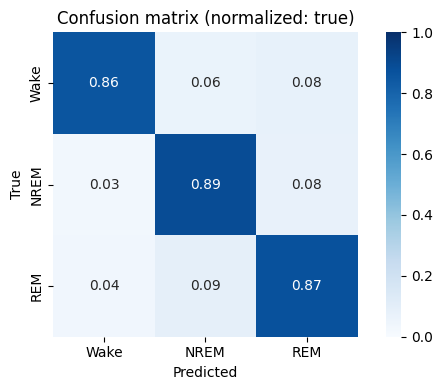

----- SMOOTHED PREDICTIONS (median kernel=5) -----
              precision    recall  f1-score   support

        Wake      0.972     0.857     0.911     45149
        NREM      0.901     0.947     0.924     46779
         REM      0.643     0.889     0.746      7621

    accuracy                          0.902     99549
   macro avg      0.839     0.898     0.860     99549
weighted avg      0.913     0.902     0.904     99549



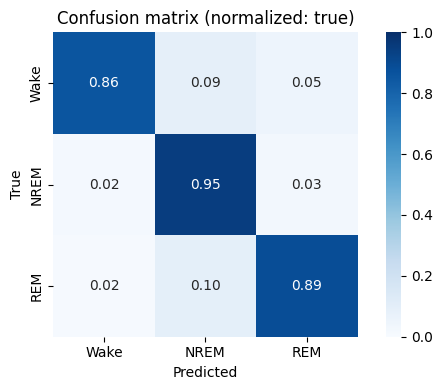

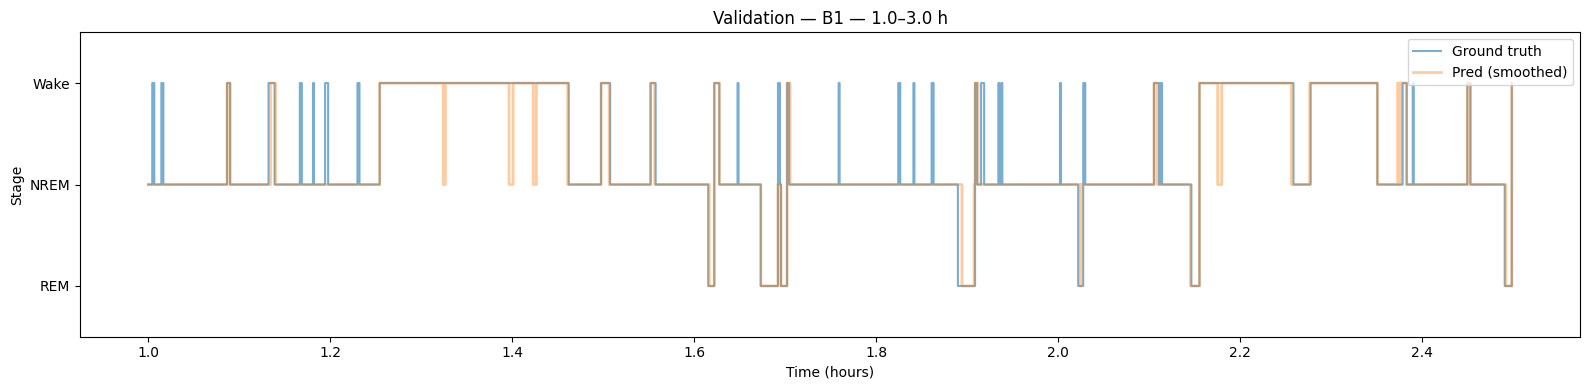

In [52]:
clf.fit(X_tr, y_tr_enc)
y_pred = clf.predict(X_va)

y_pred_enc, y_pred_smoothed_enc = evaluate_model(y_pred, 
                                                 y_va_enc, 
                                                 idx_va, 
                                                 groups, 
                                                 plot_hypno=True, 
                                                 median_kernel=5)  # returns aligned arrays

#### Test set performance

----- RAW PREDICTIONS -----
              precision    recall  f1-score   support

        Wake      0.958     0.859     0.906     32514
        NREM      0.943     0.936     0.939     36653
         REM      0.553     0.880     0.679      6109

    accuracy                          0.898     75276
   macro avg      0.818     0.892     0.841     75276
weighted avg      0.918     0.898     0.904     75276



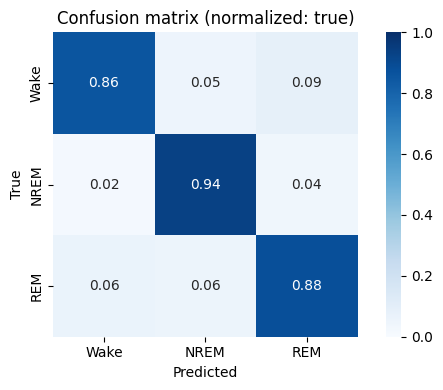

----- SMOOTHED PREDICTIONS (median kernel=5) -----
              precision    recall  f1-score   support

        Wake      0.966     0.861     0.910     32514
        NREM      0.922     0.959     0.940     36653
         REM      0.671     0.897     0.768      6109

    accuracy                          0.911     75276
   macro avg      0.853     0.905     0.873     75276
weighted avg      0.920     0.911     0.913     75276



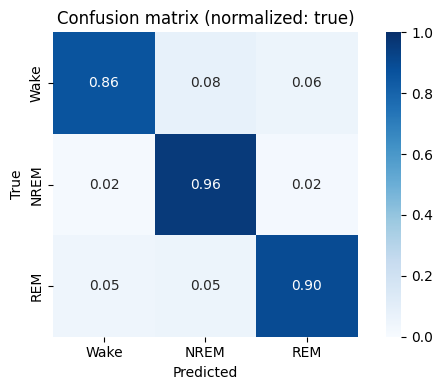

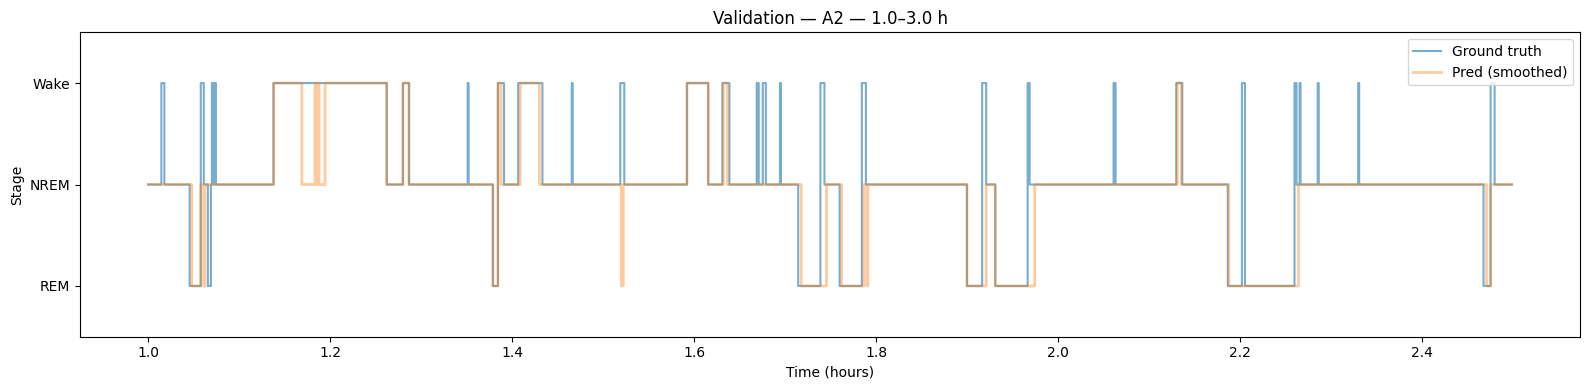

In [53]:
y_pred = clf.predict(X_te)

y_pred_enc, y_pred_smoothed_enc = evaluate_model(y_pred, 
                                                 y_te_enc, 
                                                 idx_te,
                                                 groups, 
                                                 plot_hypno=True, 
                                                 median_kernel=5)  # returns aligned arrays

### Linear Discriminant analysis

----- RAW PREDICTIONS -----
              precision    recall  f1-score   support

        Wake      0.943     0.885     0.913     45149
        NREM      0.900     0.936     0.918     46779
         REM      0.661     0.743     0.700      7621

    accuracy                          0.898     99549
   macro avg      0.835     0.854     0.843     99549
weighted avg      0.901     0.898     0.899     99549



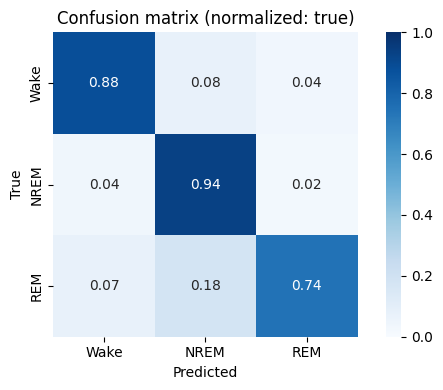

----- SMOOTHED PREDICTIONS (median kernel=5) -----
              precision    recall  f1-score   support

        Wake      0.962     0.881     0.920     45149
        NREM      0.881     0.966     0.922     46779
         REM      0.831     0.754     0.791      7621

    accuracy                          0.911     99549
   macro avg      0.892     0.867     0.877     99549
weighted avg      0.914     0.911     0.911     99549



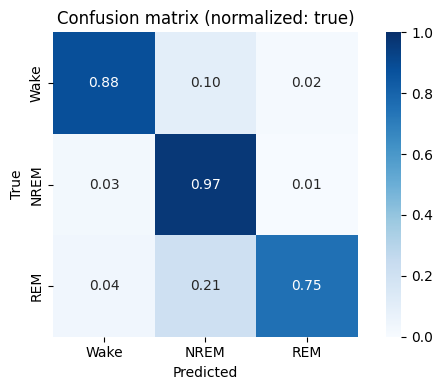

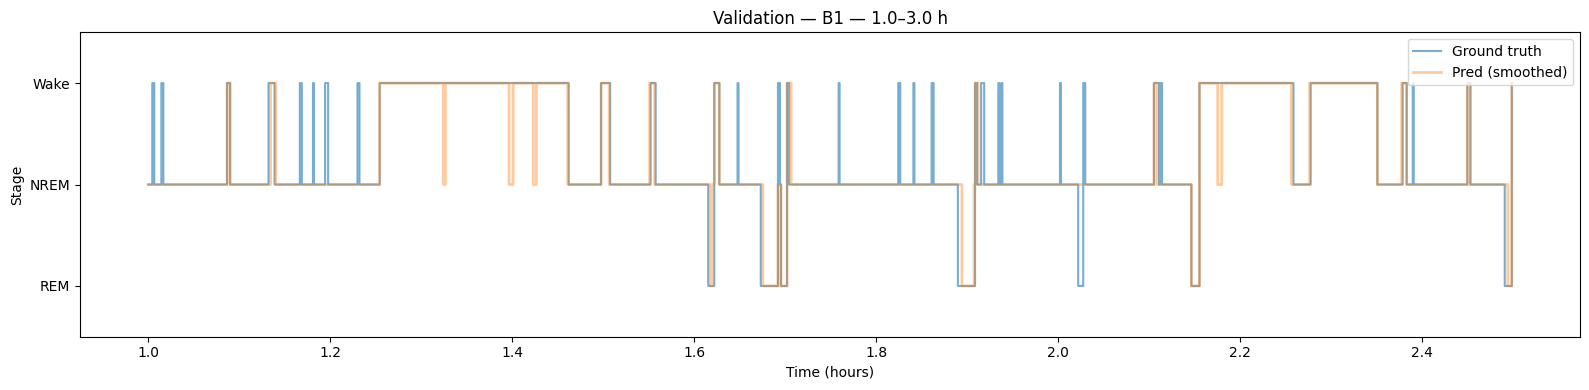

In [54]:
import numpy as np
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

clf = LinearDiscriminantAnalysis(shrinkage='auto', solver='lsqr')

clf.fit(X_tr, y_tr_enc)
y_pred = clf.predict(X_va)

y_pred_enc, y_pred_smoothed_enc = evaluate_model(y_pred, 
                                                 y_va_enc, 
                                                 idx_va,
                                                 groups, 
                                                 plot_hypno=True, 
                                                 median_kernel=5)  # returns aligned arrays

### MLP

Iteration 1, loss = 0.20909145
Iteration 2, loss = 0.16122308
Iteration 3, loss = 0.15204116
Iteration 4, loss = 0.14576703
Iteration 5, loss = 0.14078329
Iteration 6, loss = 0.13823204
Iteration 7, loss = 0.13539460
Iteration 8, loss = 0.13304823
Iteration 9, loss = 0.13126827
Iteration 10, loss = 0.12822110
Iteration 11, loss = 0.12664739
Iteration 12, loss = 0.12495956
Iteration 13, loss = 0.12341382
Iteration 14, loss = 0.12203992
Iteration 15, loss = 0.12039300
Iteration 16, loss = 0.11924039
Iteration 17, loss = 0.11710357
Iteration 18, loss = 0.11574467
Iteration 19, loss = 0.11442937
Iteration 20, loss = 0.11305976
Iteration 21, loss = 0.11076094
Iteration 22, loss = 0.10936816
Iteration 23, loss = 0.10864868
Iteration 24, loss = 0.10706680
Iteration 25, loss = 0.10495277
Iteration 26, loss = 0.10404717
Iteration 27, loss = 0.10249267
Iteration 28, loss = 0.10082176
Iteration 29, loss = 0.09928019
Iteration 30, loss = 0.09876306
Iteration 31, loss = 0.09690171
Iteration 32, los

c:\Users\MDBI\AppData\Local\miniforge3\envs\eeg-data-env\lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (50) reached and the optimization hasn't converged yet.
  warnings.warn(


----- RAW PREDICTIONS -----
              precision    recall  f1-score   support

        Wake      0.887     0.931     0.908     45149
        NREM      0.921     0.895     0.907     46779
         REM      0.777     0.687     0.729      7621

    accuracy                          0.895     99549
   macro avg      0.862     0.837     0.848     99549
weighted avg      0.895     0.895     0.894     99549



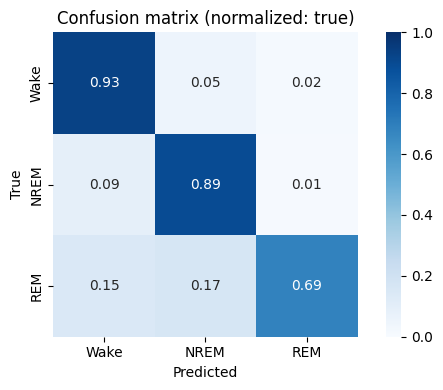

----- SMOOTHED PREDICTIONS (median kernel=5) -----
              precision    recall  f1-score   support

        Wake      0.920     0.931     0.925     45149
        NREM      0.906     0.933     0.920     46779
         REM      0.947     0.707     0.809      7621

    accuracy                          0.915     99549
   macro avg      0.924     0.857     0.885     99549
weighted avg      0.916     0.915     0.914     99549



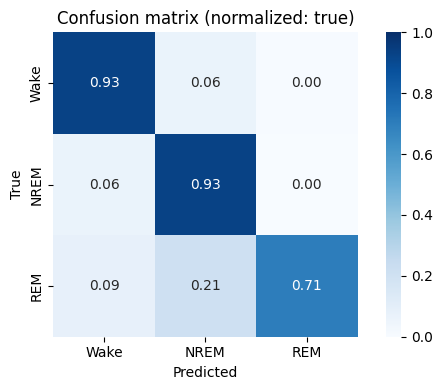

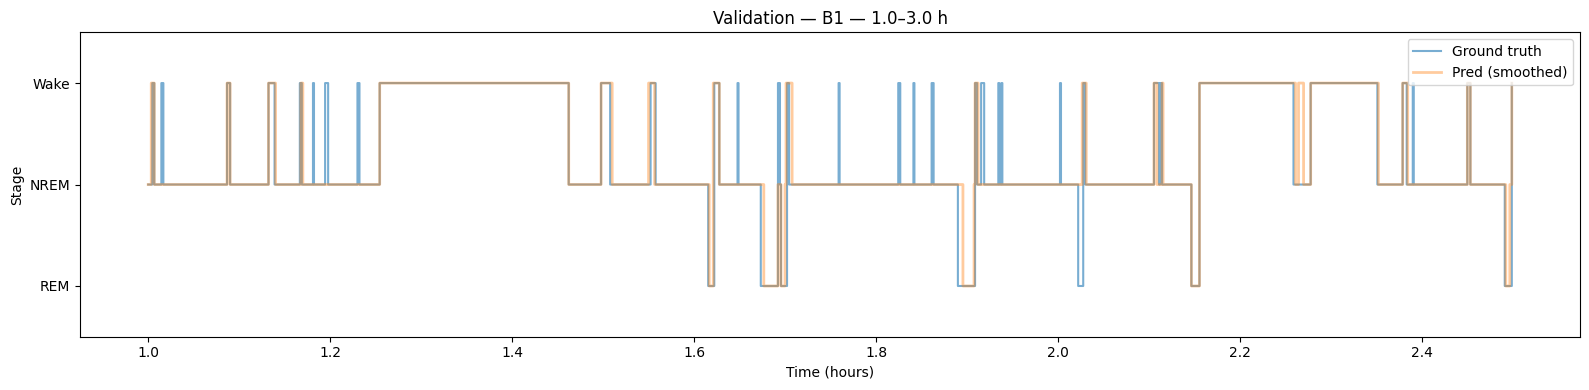

In [55]:
from sklearn.neural_network import MLPClassifier

mlp = MLPClassifier(hidden_layer_sizes=(256, 128), activation="relu",
                    alpha=1e-4, batch_size=1024, max_iter=50, verbose=True)


mlp.fit(X_tr, y_tr_enc)
y_pred = mlp.predict(X_va)

y_pred_enc, y_pred_smoothed_enc = evaluate_model(y_pred, 
                                                 y_va_enc, 
                                                 idx_va,
                                                 groups, 
                                                 plot_hypno=True, 
                                                 median_kernel=5)  # returns aligned arrays

### XGBoost

In [59]:
import numpy as np
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, accuracy_score
from xgboost import XGBClassifier
from collections import Counter

# --- per-class sample weights for imbalance (multiclass) ---
cnt = Counter(y_tr_enc)
class_weight = {k: len(y_tr_enc) / (len(cnt) * cnt[k]) for k in cnt}
w_tr = np.array([class_weight[c] for c in y_tr_enc], dtype=np.float32)

params = dict(
    n_estimators=2000,
    learning_rate=0.05,
    max_depth=6,
    min_child_weight=2,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=2.0,
    reg_alpha=0.0,
    gamma=0.0,
    tree_method="hist",   # "gpu_hist" if GPU available
    random_state=42,
    n_jobs=0,
)
eval_metric = ["mlogloss", "merror"]
model = XGBClassifier(**params)
model.fit(
    X_tr, y_tr_enc,
    eval_set=[(X_tr, y_tr_enc), (X_va, y_va_enc)],
    verbose=50,
)

# Evaluate on validation animals
y_pred = model.predict(X_va)
y_pred_enc, y_pred_smoothed_enc = evaluate_model(y_pred, 
                                                 y_va_enc, 
                                                 idx_va,
                                                 groups, 
                                                 plot_hypno=True, 
                                                 median_kernel=5)  # returns aligned arrays

[0]	validation_0-mlogloss:1.04196	validation_1-mlogloss:1.05003
[50]	validation_0-mlogloss:0.23858	validation_1-mlogloss:0.34460
[100]	validation_0-mlogloss:0.15620	validation_1-mlogloss:0.26438


KeyboardInterrupt: 